# S&P 500 Daily Stock Return and Directional Prediction with Recurrent Neural Networks

## Financial Problem Background
Predicting asset prices is a classic benchmark in machine learning and computational finance. In liquid public equity markets like the S&P 500, thousands of market participants trade continuously based on news, earnings announcements, and macroeconomic indicators.

According to the Efficient Market Hypothesis, current market prices reflect known information almost immediately. This leads to distinct empirical properties in daily financial data:
- Raw stock prices trend over long horizons and are non-stationary, making raw dollar levels poor targets for neural network regression.
- Daily percentage returns are roughly stationary, but have a very low signal-to-noise ratio: daily price movements resemble a random walk with drift.
- Asset returns exhibit fat tails (leptokurtosis), meaning extreme single-day market movements happen far more often than predicted by a standard Gaussian distribution.
- Directional price changes show near-zero autocorrelation, but squared returns show strong positive autocorrelation. This phenomenon is known as volatility clustering: turbulent days follow turbulent days, yet the sign of tomorrow's return remains difficult to anticipate.

## Learning Objectives
In this notebook, we build a recurrent neural network pipeline to predict next-day returns for 350 liquid S&P 500 stocks over a 5-year period. We will:
1. Load historical daily price and volume data and engineer stationary financial features.
2. Verify empirical stylized facts of financial returns using exploratory data analysis.
3. Construct a single-layer recurrent neural network from scratch in NumPy, calculating the forward pass and backpropagation through time.
4. Verify the analytical gradients using central finite difference gradient checking.
5. Replicate the network in TensorFlow Keras and PyTorch to confirm implementation parity.
6. Test gated architectures (LSTM and GRU) to evaluate whether gating mechanisms overcome financial noise.
7. Benchmark all models against financial baselines including the random walk (zero return) and market drift.

## 1. Environment Setup and Reproducibility

We import our numerical and deep learning libraries, initialize fixed random seeds for deterministic evaluation, and configure the training hyperparameters:
- Hidden size (H = 32): Number of hidden units in the recurrent state.
- Sequence window length (T = 30): The model observes 30 consecutive trading days (approximately 6 calendar weeks of trading history) to predict the return on day 31.
- Mini-batch size (BATCH = 128): Number of sequences processed per parameter update.
- Learning rate (LR = 0.001): Step size for the Adam optimizer.
- Gradient clipping (CLIP = 1.0): Threshold on the global norm of gradients to prevent instability during backpropagation through time.
- Early stopping patience (PATIENCE = 5): Stops training when validation loss fails to decrease for 5 consecutive epochs.

In [1]:
import os
import time
import json
import random
import warnings
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
import torch.nn as nn
import torch.nn.functional as Fn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
torch.manual_seed(SEED)

CODE = "ST"

# Resolve data and output directories
data_candidates = [
    Path("../dataset"),
    Path("../dataset/st"),
    Path("st_sp500/dataset"),
    Path("dataset/st"),
    Path("dataset")
]
DATA = next((p for p in data_candidates if (p / "all_stocks_5yr.csv").exists()), Path("../dataset"))

RES = Path("results")
IMG = Path("../report/images")
RES.mkdir(parents=True, exist_ok=True)
IMG.mkdir(parents=True, exist_ok=True)

# Hyperparameters
H = 32
BATCH = 128
LR = 1e-3
EPS = 1e-7
CLIP = 1.0
PATIENCE = 5
MAX_EPOCHS = 30
T = 30

dev = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Environment initialized successfully:")
print(f"  PyTorch version: {torch.__version__} (Device: {dev})")
print(f"  TensorFlow version: {tf.__version__} | Keras version: {keras.__version__}")


Environment initialized successfully:
  PyTorch version: 2.14.1+cpu (Device: cpu)
  TensorFlow version: 2.22.0-rc0 | Keras version: 3.16.0.dev2026100304


## 2. Financial Data Ingestion and Feature Engineering

The raw dataset contains daily open, high, low, close, and volume quotes for S&P 500 member companies from February 2013 through February 2018.

To construct a balanced panel across time:
1. We filter for companies that have complete records across all 1,259 trading days.
2. We rank companies by average daily dollar volume (close price multiplied by share volume) and retain the top 350 most liquid tickers.
3. Missing intraday values (open, high, low) on a handful of records are imputed with that day's closing price.

For each stock on each trading day, we construct four stationary features:
1. Daily log return:
   $$r_t = \ln\left(\frac{\text{Close}_t}{\text{Close}_{t-1}}\right)$$
   Log returns are time-additive and symmetric: a +1% move followed by a -1% move correctly reflects the net compounding.
2. High-Low relative price range:
   $$\text{range}_t = \frac{\text{High}_t - \text{Low}_t}{\text{Close}_t}$$
   This captures intraday volatility and price dispersion.
3. Open-to-Close intraday return:
   $$\text{oc}_t = \ln\left(\frac{\text{Close}_t}{\text{Open}_t}\right)$$
   This reflects price movement during the official exchange trading session.
4. Normalized trading volume: Log volume standardized on a per-ticker basis to account for varying share counts across companies.

In [2]:
N_SERIES = 350

raw_path = DATA / "all_stocks_5yr.csv"
raw = pd.read_csv(raw_path, parse_dates=["date"])

ticker_counts = raw.groupby("Name").size()
complete_tickers = ticker_counts[ticker_counts == ticker_counts.max()].index
raw = raw[raw.Name.isin(complete_tickers)]

mean_dollar_volume = (raw.close * raw.volume).groupby(raw.Name).mean()
top_tickers = mean_dollar_volume.nlargest(N_SERIES).index

print(f"Total raw records: {len(raw):,}")
print(f"Tickers with full 1,259-day history: {len(complete_tickers)}")
print(f"Selected most liquid tickers: {len(top_tickers)}")

def pivot_column(col_name):
    return raw.pivot(index="date", columns="Name", values=col_name)[top_tickers]

close_df = pivot_column("close")
open_df = pivot_column("open").fillna(close_df)
high_df = pivot_column("high").fillna(close_df)
low_df = pivot_column("low").fillna(close_df)
volume_df = pivot_column("volume")

calendar_dates = close_df.index.to_numpy()
num_stocks = len(top_tickers)

close_prices = close_df.to_numpy().T
raw_returns = np.diff(np.log(close_prices), axis=1)
total_trading_days = raw_returns.shape[1]
trading_dates = calendar_dates[1:]

high_low_ratio = ((high_df - low_df) / close_df).to_numpy().T[:, 1:]
open_close_return = np.log(close_df / open_df).to_numpy().T[:, 1:]
log_volume = np.log1p(volume_df.to_numpy().T)[:, 1:]

print(f"Engineered panel of {num_stocks} stocks over {total_trading_days} return days.")

Total raw records: 591,730
Tickers with full 1,259-day history: 470
Selected most liquid tickers: 350


Engineered panel of 350 stocks over 1258 return days.


### Chronological Data Splitting and Feature Normalization

We divide the 1,258 trading days chronologically across all stocks simultaneously:
- Training period: First 70% of days (approx. 880 trading days).
- Validation period: Next 15% of days (approx. 189 trading days).
- Test period: Final 15% of days (approx. 189 trading days).

To ensure zero information leakage, normalization statistics are calculated strictly on the training period:
- Features 0, 1, and 2 (return, high-low range, and open-close return) are normalized using the aggregate mean and standard deviation from the training days.
- Feature 3 (volume) is normalized per ticker using each ticker's own training-period mean and standard deviation.

We then construct sliding windows of length $T = 30$ trading days to forecast the return at step $t+1$.

In [3]:
split_train = int(0.70 * total_trading_days)
split_val = int(0.85 * total_trading_days)

FEATURE_NAMES = ["ret", "hl_range", "oc_ret", "vol_z"]
S = np.stack([raw_returns, high_low_ratio, open_close_return, log_volume], axis=-1).astype(np.float32)

train_features_slice = S[:, :split_train, :3].reshape(-1, 3)
feat_mean = train_features_slice.mean(axis=0)
feat_std = train_features_slice.std(axis=0)

S[..., :3] = (S[..., :3] - feat_mean) / feat_std

vol_train_mean = S[:, :split_train, 3].mean(axis=1, keepdims=True)
vol_train_std = S[:, :split_train, 3].std(axis=1, keepdims=True)
S[..., 3] = (S[..., 3] - vol_train_mean) / vol_train_std

target_mean = float(feat_mean[0])
target_std = float(feat_std[0])

def make_windows(start_day, end_day):
    """Extract sequence windows whose target day t+1 falls within [start_day, end_day)."""
    target_endpoints = np.arange(max(start_day - 1, T - 1), end_day - 1)
    X_list = [S[:, t - T + 1:t + 1] for t in target_endpoints]
    y_list = [S[:, t + 1, 0] for t in target_endpoints]
    
    X_arr = np.concatenate(X_list, axis=0)
    y_arr = np.concatenate(y_list, axis=0)
    day_indices = np.repeat(target_endpoints + 1, num_stocks)
    stock_indices = np.tile(np.arange(num_stocks), len(target_endpoints))
    return X_arr, y_arr, day_indices, stock_indices

Xtr, ytr, tr_day, tr_ser = make_windows(0, split_train)
Xva, yva, va_day, va_ser = make_windows(split_train, split_val)
Xte, yte, te_day, te_ser = make_windows(split_val, total_trading_days)

np.savez(
    DATA / "splits.npz",
    days=trading_dates,
    series=np.array(top_tickers),
    c1=split_train,
    c2=split_val,
    T=T,
    mu=feat_mean,
    sd=feat_std
)

print(f"Training windows:   {len(Xtr):,} (Shape: {Xtr.shape})")
print(f"Validation windows: {len(Xva):,} (Shape: {Xva.shape})")
print(f"Test windows:       {len(Xte):,} (Shape: {Xte.shape})")
print(f"Split dates: Train < {str(trading_dates[split_train])[:10]} <= Validation < {str(trading_dates[split_val])[:10]} <= Test")

Training windows:   297,500 (Shape: (297500, 30, 4))
Validation windows: 66,150 (Shape: (66150, 30, 4))
Test windows:       66,150 (Shape: (66150, 30, 4))
Split dates: Train < 2016-08-09 <= Validation < 2017-05-10 <= Test


### Financial Metrics and Market Benchmarks

Evaluating financial models requires metrics suited to asset returns:
1. Root Mean Squared Error (RMSE): Measured in real log-return units.
2. Out-of-sample $R^2$: Quantifies variance explained relative to predicting the historical mean return.
3. Directional Accuracy: The percentage of days on which the model correctly anticipates whether the stock closes up ($r > 0$) or down ($r < 0$). This is the critical metric for long/short market trading.
4. Information Coefficient (IC): The Pearson correlation between predicted returns and realized returns across test windows.

We benchmark all models against four standard financial baselines:
- Zero return: The theoretical random walk forecast ($\\hat{r} = 0$).
- Always up: Exploits long-term upward market drift by predicting a small positive return on every day.
- Previous-day return: A simple short-term momentum heuristic ($\\hat{r}_{t+1} = r_t$).
- Training mean: The average return observed during the training period.

In [4]:
def to_real_returns(z_scores):
    """Invert z-score standardization back to physical log returns."""
    return np.asarray(z_scores) * target_std + target_mean

KEY_METRIC = "rmse"

def compute_financial_metrics(z_true, z_pred):
    """Compute regression and directional trading metrics."""
    real_true = to_real_returns(z_true)
    real_pred = to_real_returns(z_pred)
    
    rmse_val = float(np.sqrt(np.mean((real_true - real_pred) ** 2)))
    mae_val = float(np.mean(np.abs(real_true - real_pred)))
    
    total_var = np.sum(z_true ** 2)
    residual_var = np.sum((z_true - z_pred) ** 2)
    r2_oos = float(1.0 - residual_var / total_var)
    
    if np.std(real_pred) > 1e-12:
        dir_accuracy = float(np.mean(np.sign(real_pred) == np.sign(real_true)))
        ic_val = float(np.corrcoef(real_true, real_pred)[0, 1])
    else:
        dir_accuracy = float("nan")
        ic_val = float("nan")
        
    return {
        "rmse": rmse_val,
        "mae": mae_val,
        "r2_oos": r2_oos,
        "dir_acc": dir_accuracy,
        "ic": ic_val
    }

z_zero = float((0.0 - target_mean) / target_std)
z_drift = float((1e-6 - target_mean) / target_std)

BASELINES = {
    "zero return": np.full(len(yte), z_zero, dtype=np.float32),
    "always up (+1e-6)": np.full(len(yte), z_drift, dtype=np.float32),
    "previous-day return": Xte[:, -1, 0],
    "train mean": np.zeros(len(yte), dtype=np.float32)
}

DISPLAY_STOCK_INDEX = int(np.where(np.array(top_tickers) == "AAPL")[0][0]) if "AAPL" in set(top_tickers) else 0

def get_stock_test_slice(predictions, num_points=120):
    """Extract actual vs predicted test returns for the primary display ticker."""
    indices = np.where(te_ser == DISPLAY_STOCK_INDEX)[0][-num_points:]
    dates = trading_dates[te_day[indices]]
    actual_ret = to_real_returns(yte[indices])
    pred_ret = to_real_returns(predictions[indices])
    title = f"Daily return: {top_tickers[DISPLAY_STOCK_INDEX]}"
    return dates, actual_ret, pred_ret, title

up_percentage = float(np.mean(to_real_returns(yte) > 0)) * 100.0
print(f"Percentage of positive-return trading days in test period: {up_percentage:.2f}%")

Percentage of positive-return trading days in test period: 53.06%


## 3. Financial Exploratory Data Analysis

Asset returns behave very differently from conventional industrial or commercial time series. We visualize three stylized facts of financial markets:
1. Non-stationarity of prices: Normalized price paths show long-term upward drift with periods of major drawdown.
2. Heavy tails (leptokurtosis): Daily log returns display extreme outliers far beyond what a Gaussian normal distribution predicts.
3. Volatility clustering: Raw returns have virtually zero autocorrelation, meaning yesterday's return does not reliably predict tomorrow's direction. In contrast, squared returns show strong positive autocorrelation, confirming that volatility clusters in time.

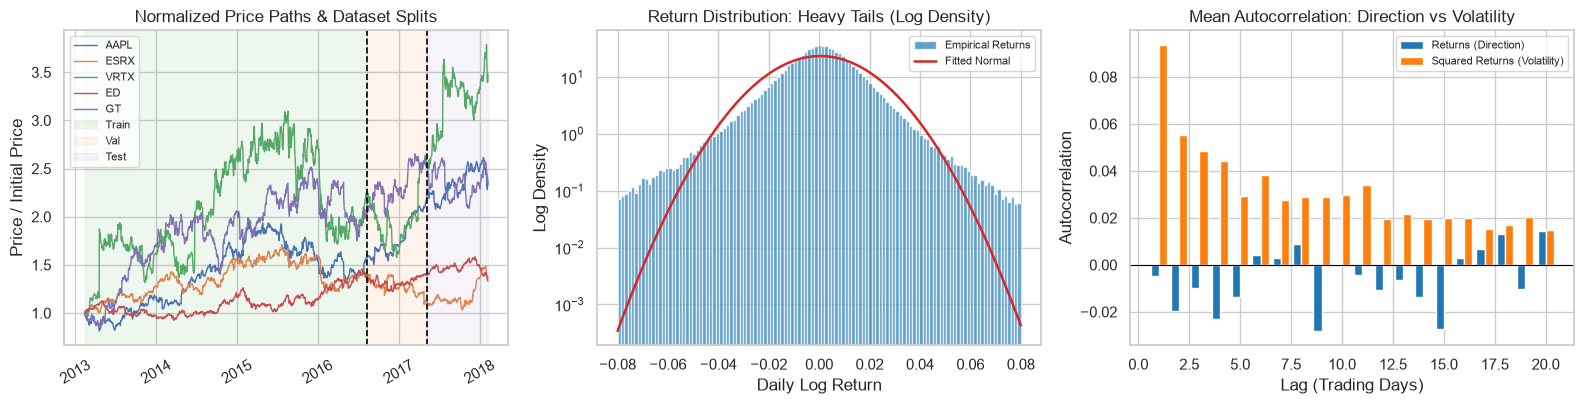

Daily return std: 0.0170 | Excess kurtosis: 54.2 (Normal distribution = 0)
Lag-1 return autocorrelation: -0.0049 (near zero: market efficiency)
Lag-1 squared return autocorrelation: 0.0937 (positive: volatility clustering)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

sample_ticker_indices = np.linspace(0, num_stocks - 1, 5).astype(int)
for idx in sample_ticker_indices:
    ticker_name = top_tickers[idx]
    normalized_price = close_prices[idx, 1:] / close_prices[idx, 1]
    axes[0].plot(trading_dates, normalized_price, lw=1.0, label=ticker_name)
    
axes[0].axvline(trading_dates[split_train], color="black", linestyle="--", lw=1.2)
axes[0].axvline(trading_dates[split_val], color="black", linestyle="--", lw=1.2)
axes[0].axvspan(trading_dates[0], trading_dates[split_train], color="#2ca02c", alpha=0.08, label="Train")
axes[0].axvspan(trading_dates[split_train], trading_dates[split_val], color="#ff7f0e", alpha=0.08, label="Val")
axes[0].axvspan(trading_dates[split_val], trading_dates[-1], color="#9467bd", alpha=0.08, label="Test")
axes[0].set_title("Normalized Price Paths & Dataset Splits")
axes[0].set_ylabel("Price / Initial Price")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(loc="upper left", fontsize=8)

train_returns_flat = raw_returns[:, :split_train].ravel()
x_grid = np.linspace(-0.08, 0.08, 400)
mean_ret = train_returns_flat.mean()
std_ret = train_returns_flat.std()
normal_curve = np.exp(-0.5 * ((x_grid - mean_ret) / std_ret) ** 2) / (std_ret * np.sqrt(2 * np.pi))

axes[1].hist(train_returns_flat, bins=np.linspace(-0.08, 0.08, 120), density=True, color="#1f77b4", alpha=0.7, label="Empirical Returns")
axes[1].plot(x_grid, normal_curve, color="#d62728", lw=1.8, label="Fitted Normal")
axes[1].set_yscale("log")
axes[1].set_title("Return Distribution: Heavy Tails (Log Density)")
axes[1].set_xlabel("Daily Log Return")
axes[1].set_ylabel("Log Density")
axes[1].legend(fontsize=8)

def compute_mean_acf(series_matrix, max_lags=20):
    acf_list = []
    for lag in range(1, max_lags + 1):
        corrs = [np.corrcoef(series[:-lag], series[lag:])[0, 1] for series in series_matrix]
        acf_list.append(np.mean(corrs))
    return np.array(acf_list)

lags_range = np.arange(1, 21)
acf_raw = compute_mean_acf(raw_returns[:, :split_train], 20)
acf_squared = compute_mean_acf(raw_returns[:, :split_train] ** 2, 20)

axes[2].bar(lags_range - 0.2, acf_raw, width=0.4, color="#1f77b4", label="Returns (Direction)")
axes[2].bar(lags_range + 0.2, acf_squared, width=0.4, color="#ff7f0e", label="Squared Returns (Volatility)")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("Mean Autocorrelation: Direction vs Volatility")
axes[2].set_xlabel("Lag (Trading Days)")
axes[2].set_ylabel("Autocorrelation")
axes[2].legend(fontsize=8)

plt.tight_layout()
fig.savefig(IMG / f"{CODE}_eda_returns.png")
plt.show()

excess_kurt = float(((train_returns_flat - mean_ret) ** 4).mean() / (std_ret ** 4) - 3.0)
print(f"Daily return std: {std_ret:.4f} | Excess kurtosis: {excess_kurt:.1f} (Normal distribution = 0)")
print(f"Lag-1 return autocorrelation: {acf_raw[0]:.4f} (near zero: market efficiency)")
print(f"Lag-1 squared return autocorrelation: {acf_squared[0]:.4f} (positive: volatility clustering)")

## 4. Recurrent Neural Network from Scratch in NumPy

### Recurrent Model Architecture
The single-layer vanilla RNN updates its 32-dimensional hidden memory vector $h_t$ at each day $t = 1, \dots, 30$:
$$h_t = \tanh\left(x_t W_{xh} + h_{t-1} W_{hh} + b_h\right)$$
with initial state $h_0 = \mathbf{0}$. The output layer projects the final state $h_T$ into a predicted return:
$$\hat{y} = h_T W_{hy} + b_y$$

For $F = 4$ financial features and $H = 32$ hidden units, the network has:
- $W_{xh}$: $4 \times 32 = 128$
- $W_{hh}$: $32 \times 32 = 1{,}024$
- $b_h$: $32$
- $W_{hy}$: $32 \times 1 = 32$
- $b_y$: $1$
- Total parameters: $128 + 1024 + 32 + 32 + 1 = 1{,}217$

In [6]:
class ScratchRNN:
    def __init__(self, num_features, hidden_dim, seed=SEED, dtype=np.float32):
        rng = np.random.default_rng(seed)
        
        limit_x = np.sqrt(6.0 / (num_features + hidden_dim))
        gaussian_matrix = rng.standard_normal((hidden_dim, hidden_dim))
        q_orth, r_tri = np.linalg.qr(gaussian_matrix)
        orthogonal_matrix = q_orth * np.sign(np.diag(r_tri))
        limit_y = np.sqrt(6.0 / (hidden_dim + 1))
        
        self.p = {
            "Wxh": rng.uniform(-limit_x, limit_x, (num_features, hidden_dim)),
            "Whh": orthogonal_matrix,
            "bh": np.zeros(hidden_dim),
            "Why": rng.uniform(-limit_y, limit_y, (hidden_dim, 1)),
            "by": np.zeros(1)
        }
        self.p = {k: v.astype(dtype) for k, v in self.p.items()}

    def count_parameters(self):
        return int(sum(val.size for val in self.p.values()))

    def forward(self, X):
        num_samples, seq_len, _ = X.shape
        hidden_dim = self.p["Whh"].shape[0]
        
        input_projected = X @ self.p["Wxh"]
        h_current = np.zeros((num_samples, hidden_dim), dtype=X.dtype)
        hidden_history = [h_current]
        
        for t in range(seq_len):
            linear_sum = input_projected[:, t] + h_current @ self.p["Whh"] + self.p["bh"]
            h_current = np.tanh(linear_sum)
            hidden_history.append(h_current)
            
        y_hat = (h_current @ self.p["Why"] + self.p["by"])[:, 0]
        return y_hat, hidden_history

    def loss_and_gradients(self, X, y):
        num_samples, seq_len, _ = X.shape
        y_hat, hidden_history = self.forward(X)
        
        error = y_hat - y
        loss_val = float(np.mean(error ** 2))
        
        d_yhat = (2.0 / num_samples) * error[:, None]
        
        grads = {k: np.zeros_like(v) for k, v in self.p.items()}
        grads["Why"] = hidden_history[-1].T @ d_yhat
        grads["by"] = d_yhat.sum(axis=0)
        
        d_h = d_yhat @ self.p["Why"].T
        grad_norms = np.zeros(seq_len)
        
        for t in range(seq_len, 0, -1):
            grad_norms[t - 1] = np.linalg.norm(d_h)
            d_z = d_h * (1.0 - hidden_history[t] ** 2)
            
            grads["Wxh"] += X[:, t - 1].T @ d_z
            grads["Whh"] += hidden_history[t - 1].T @ d_z
            grads["bh"] += d_z.sum(axis=0)
            
            d_h = d_z @ self.p["Whh"].T
            
        return loss_val, grads, grad_norms

    def predict(self, X, batch_size=4096):
        predictions = []
        for i in range(0, len(X), batch_size):
            batch_pred, _ = self.forward(X[i:i + batch_size])
            predictions.append(batch_pred)
        return np.concatenate(predictions)


class NumpyAdam:
    def __init__(self, parameters, lr=LR, beta1=0.9, beta2=0.999, eps=EPS):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0
        self.m = {k: np.zeros_like(v) for k, v in parameters.items()}
        self.v = {k: np.zeros_like(v) for k, v in parameters.items()}

    def step(self, parameters, gradients):
        self.t += 1
        for k in parameters:
            self.m[k] = self.beta1 * self.m[k] + (1.0 - self.beta1) * gradients[k]
            self.v[k] = self.beta2 * self.v[k] + (1.0 - self.beta2) * (gradients[k] ** 2)
            
            m_hat = self.m[k] / (1.0 - self.beta1 ** self.t)
            v_hat = self.v[k] / (1.0 - self.beta2 ** self.t)
            
            parameters[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


def apply_gradient_clipping(gradients, max_norm=CLIP):
    total_norm = np.sqrt(sum(float((g.astype(np.float64) ** 2).sum()) for g in gradients.values()))
    scale = min(1.0, max_norm / (total_norm + 1e-6))
    for k in gradients:
        gradients[k] *= scale
    return total_norm


def train_scratch_model(model, X_train, y_train, X_val, y_val):
    optimizer = NumpyAdam(model.p)
    rng = np.random.default_rng(SEED)
    
    history = {"loss": [], "val_loss": []}
    epoch_durations = []
    best_loss = np.inf
    patience_counter = 0
    best_weights = None
    
    total_start = time.perf_counter()
    num_train = len(X_train)
    
    for epoch in range(MAX_EPOCHS):
        epoch_start = time.perf_counter()
        permutation = rng.permutation(num_train)
        running_loss = 0.0
        
        for i in range(0, num_train, BATCH):
            batch_idx = permutation[i:i + BATCH]
            loss, grads, _ = model.loss_and_gradients(X_train[batch_idx], y_train[batch_idx])
            apply_gradient_clipping(grads)
            optimizer.step(model.p, grads)
            running_loss += loss * len(batch_idx)
            
        epoch_loss = running_loss / num_train
        val_pred = model.predict(X_val)
        val_loss = float(np.mean((val_pred - y_val) ** 2))
        
        history["loss"].append(epoch_loss)
        history["val_loss"].append(val_loss)
        epoch_durations.append(time.perf_counter() - epoch_start)
        
        if val_loss < best_loss - 1e-12:
            best_loss = val_loss
            patience_counter = 0
            best_weights = {k: v.copy() for k, v in model.p.items()}
        else:
            patience_counter += 1
            
        if patience_counter >= PATIENCE:
            break
            
    model.p = best_weights
    total_time = time.perf_counter() - total_start
    return history, epoch_durations, total_time

### Numerical Gradient Verification

We compare analytical Backpropagation Through Time gradients against central finite differences across all 1,217 parameters in float64 precision. The maximum relative discrepancy must be below $10^{-5}$.

In [7]:
def run_gradient_check(num_features, num_samples=8, epsilon=1e-6, seed=0):
    check_model = ScratchRNN(num_features, H, seed=seed, dtype=np.float64)
    for bias_key in ("bh", "by"):
        check_model.p[bias_key] = np.random.default_rng(1).normal(0, 0.1, check_model.p[bias_key].shape)
        
    X_sample = Xtr[:num_samples].astype(np.float64)
    y_sample = ytr[:num_samples].astype(np.float64)
    
    _, analytic_grads, _ = check_model.loss_and_gradients(X_sample, y_sample)
    results = []
    
    for param_name, param_tensor in check_model.p.items():
        numerical_grad = np.zeros_like(param_tensor)
        for idx in np.ndindex(*param_tensor.shape):
            orig_val = param_tensor[idx]
            
            param_tensor[idx] = orig_val + epsilon
            loss_pos = check_model.loss_and_gradients(X_sample, y_sample)[0]
            
            param_tensor[idx] = orig_val - epsilon
            loss_neg = check_model.loss_and_gradients(X_sample, y_sample)[0]
            
            param_tensor[idx] = orig_val
            numerical_grad[idx] = (loss_pos - loss_neg) / (2.0 * epsilon)
            
        max_analytic = max(np.abs(analytic_grads[param_name]).max(), 1e-12)
        relative_error = np.abs(analytic_grads[param_name] - numerical_grad).max() / max_analytic
        results.append((param_name, param_tensor.shape, float(relative_error)))
        
    return pd.DataFrame(results, columns=["Parameter", "Shape", "Relative Error"])

gc_df = run_gradient_check(Xtr.shape[2])
display(gc_df)
max_error = gc_df["Relative Error"].max()
print(f"Maximum relative error: {max_error:.2e}")
assert max_error < 1e-5, "BPTT gradient check failed!"
print("Gradient check passed: Analytical BPTT gradients are numerically exact.")

,Parameter,Shape,Relative Error
0,Wxh,"(4, 32)",8.590652e-10
1,Whh,"(32, 32)",8.302950e-10
2,bh,"(32,)",1.579790e-09
3,Why,"(32, 1)",3.405910e-10
4,by,"(1,)",1.918839e-10


Maximum relative error: 1.58e-09
Gradient check passed: Analytical BPTT gradients are numerically exact.


### Training the Scratch RNN on Financial Returns

We initialize the model with reference weights `W0` and train it using our custom Adam optimizer.

In [8]:
RUNS = {}

def compute_median_epoch_time(times):
    times_list = list(times)
    return float(np.median(times_list[1:] if len(times_list) > 1 else times_list))

def benchmark_inference_speed(predict_func, X_test, num_reps=3):
    sample_size = min(len(X_test), 10000)
    durations = []
    for _ in range(num_reps):
        t_start = time.perf_counter()
        predict_func(X_test[:sample_size])
        durations.append(time.perf_counter() - t_start)
    return float(np.median(durations)) / sample_size * 1e6

def plot_training_loss(run_identifier, training_history):
    best_epoch_idx = int(np.argmin(training_history["val_loss"]))
    fig, ax = plt.subplots(figsize=(6, 3.6))
    epochs_range = range(1, len(training_history["loss"]) + 1)
    ax.plot(epochs_range, training_history["loss"], label="Train MSE", color="#1f77b4", lw=1.5)
    ax.plot(epochs_range, training_history["val_loss"], label="Val MSE", color="#ff7f0e", lw=1.5)
    ax.axvline(best_epoch_idx + 1, linestyle=":", color="grey", label=f"Best (Epoch {best_epoch_idx+1})")
    ax.set_title(f"{run_identifier}: Training & Validation Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss (MSE)")
    ax.legend(fontsize=9)
    plt.tight_layout()
    fig.savefig(IMG / f"{run_identifier}_loss.png")
    plt.show()

def plot_forecast_and_residuals(run_identifier, test_predictions):
    dates, actual_vals, pred_vals, series_title = get_stock_test_slice(test_predictions)
    fig, (ax_ts, ax_res) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
    
    ax_ts.plot(dates, actual_vals, label="Actual Return", color="black", lw=1.2)
    ax_ts.plot(dates, pred_vals, label=f"Predicted ({run_identifier})", color="#1f77b4", lw=1.4, linestyle="--")
    ax_ts.set_title(f"{run_identifier}: Forecast on Test Slice")
    ax_ts.set_ylabel("Daily Log Return")
    ax_ts.tick_params(axis="x", rotation=30)
    ax_ts.legend(fontsize=8)
    
    residual_errors = yte - test_predictions
    sns.histplot(residual_errors, bins=60, kde=True, ax=ax_res, color="#2ca02c")
    ax_res.axvline(0, color="red", linestyle="--", lw=1)
    ax_res.set_title("Test Residual Distribution")
    ax_res.set_xlabel("Error (Standardized Units)")
    
    plt.tight_layout()
    fig.savefig(IMG / f"{run_identifier}_forecast.png")
    plt.show()

def record_and_evaluate_run(run_id, framework, model_type, history, param_count, epoch_times, total_sec, predict_fn):
    val_preds = predict_fn(Xva)
    test_preds = predict_fn(Xte)
    val_metrics = compute_financial_metrics(yva, val_preds)
    test_metrics = compute_financial_metrics(yte, test_preds)
    
    best_epoch = int(np.argmin(history["val_loss"]) + 1)
    median_s_epoch = compute_median_epoch_time(epoch_times)
    infer_ms = benchmark_inference_speed(predict_fn, Xte)
    
    record = {
        "run_id": run_id,
        "impl": framework,
        "model": model_type,
        "params": int(param_count),
        "epochs_run": len(history["loss"]),
        "best_epoch": best_epoch,
        "time_per_epoch_s": median_s_epoch,
        "total_time_s": float(total_sec),
        "infer_ms_per_1k": infer_ms,
        "val": val_metrics,
        "test": test_metrics,
        "history": {k: [float(v) for v in vals] for k, vals in history.items()}
    }
    
    (RES / f"{run_id}.json").write_text(json.dumps(record, indent=2))
    RUNS[run_id] = dict(record, pred=test_preds)
    
    plot_training_loss(run_id, history)
    plot_forecast_and_residuals(run_id, test_preds)
    
    dir_acc_str = f"{test_metrics['dir_acc']:.2%}" if not np.isnan(test_metrics['dir_acc']) else "N/A"
    print(f"[{run_id}] Parameters: {param_count:,} | Epochs: {record['epochs_run']} | "
          f"Speed: {median_s_epoch:.1f} s/epoch | Test RMSE: {test_metrics['rmse']:.4f} | "
          f"Dir Accuracy: {dir_acc_str} | R2: {test_metrics['r2_oos']:.3f}")
    return record

Scratch RNN initialized with 1,217 trainable parameters.


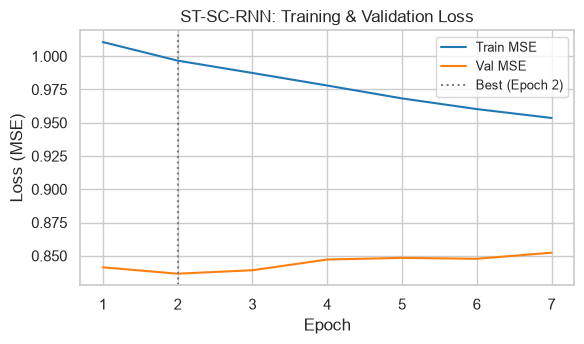

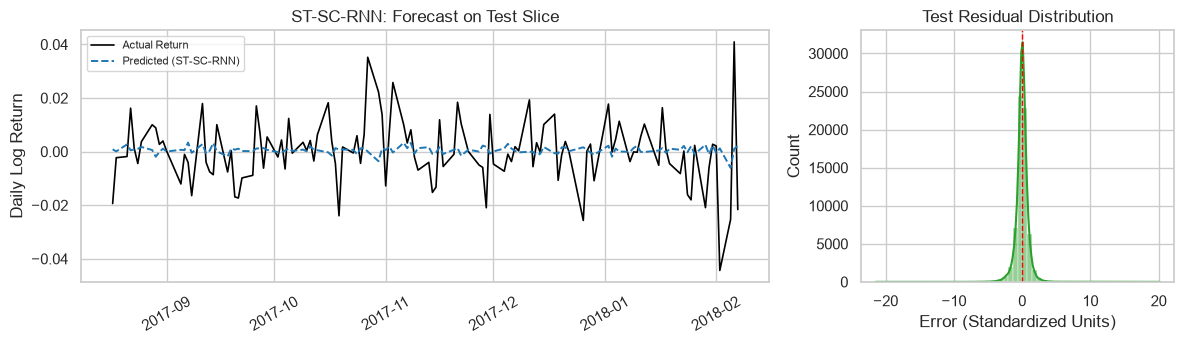

[ST-SC-RNN] Parameters: 1,217 | Epochs: 7 | Speed: 4.0 s/epoch | Test RMSE: 0.0159 | Dir Accuracy: 50.84% | R2: -0.017


In [9]:
F_features = Xtr.shape[2]
scratch_model = ScratchRNN(F_features, H)
W0 = {k: v.copy() for k, v in scratch_model.p.items()}

print(f"Scratch RNN initialized with {scratch_model.count_parameters():,} trainable parameters.")
sc_history, sc_times, sc_total_time = train_scratch_model(scratch_model, Xtr, ytr, Xva, yva)

record_and_evaluate_run(
    run_id=f"{CODE}-SC-RNN",
    framework="Scratch",
    model_type="RNN",
    history=sc_history,
    param_count=scratch_model.count_parameters(),
    epoch_times=sc_times,
    total_sec=sc_total_time,
    predict_fn=scratch_model.predict
);

### Visualizing Gradient Flow Across the Lookback Window

We inspect the decay of gradient norms backwards across the 30-day lookback sequence.

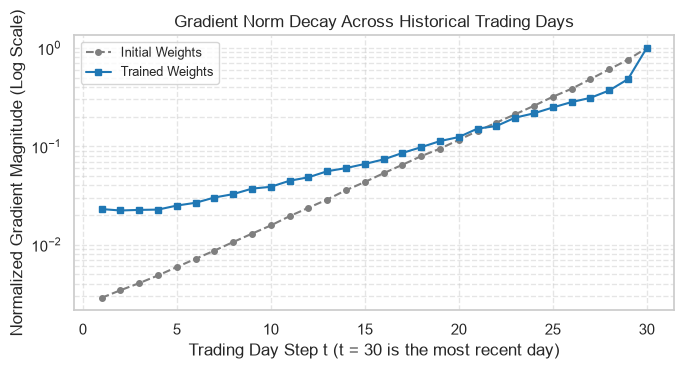

Gradient reaching day 1 relative to day 30: 2.298% (Trained) vs 0.288% (Initial)


In [10]:
sample_indices = np.random.default_rng(0).choice(len(Xte), 512, replace=False)
trained_weights = scratch_model.p
_, _, norms_trained = scratch_model.loss_and_gradients(Xte[sample_indices], yte[sample_indices])

scratch_model.p = ScratchRNN(F_features, H).p
_, _, norms_init = scratch_model.loss_and_gradients(Xte[sample_indices], yte[sample_indices])
scratch_model.p = trained_weights

fig, ax = plt.subplots(figsize=(7, 3.8))
time_steps = range(1, T + 1)
ax.semilogy(time_steps, norms_init / norms_init[-1], marker="o", ms=4, label="Initial Weights", color="#7f7f7f", linestyle="--")
ax.semilogy(time_steps, norms_trained / norms_trained[-1], marker="s", ms=4, label="Trained Weights", color="#1f77b4")
ax.set_title("Gradient Norm Decay Across Historical Trading Days")
ax.set_xlabel("Trading Day Step t (t = 30 is the most recent day)")
ax.set_ylabel("Normalized Gradient Magnitude (Log Scale)")
ax.legend(fontsize=9)
ax.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
fig.savefig(IMG / f"{CODE}-SC-RNN_gradnorm.png")
plt.show()

print(f"Gradient reaching day 1 relative to day 30: "
      f"{norms_trained[0] / norms_trained[-1]:.3%} (Trained) vs {norms_init[0] / norms_init[-1]:.3%} (Initial)")

## 5. Recurrent Neural Networks in TensorFlow Keras

We implement Keras models for the vanilla RNN, LSTM, and GRU.

In [11]:
def build_keras_model(model_kind, num_features, seq_length, initial_weights=None):
    keras.utils.set_random_seed(SEED)
    inputs = keras.Input(shape=(seq_length, num_features))
    
    if model_kind == "RNN":
        rnn_layer = layers.SimpleRNN(H, return_sequences=False)
    elif model_kind == "LSTM":
        rnn_layer = layers.LSTM(H, return_sequences=False)
    elif model_kind == "GRU":
        rnn_layer = layers.GRU(H, return_sequences=False)
    else:
        raise ValueError(f"Unknown model kind: {model_kind}")
        
    hidden = rnn_layer(inputs)
    outputs = layers.Dense(1)(hidden)
    model = keras.Model(inputs=inputs, outputs=outputs)
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR, epsilon=EPS, global_clipnorm=CLIP),
        loss="mse"
    )
    
    if initial_weights is not None and model_kind == "RNN":
        model.layers[1].set_weights([
            initial_weights["Wxh"],
            initial_weights["Whh"],
            initial_weights["bh"]
        ])
        model.layers[2].set_weights([
            initial_weights["Why"],
            initial_weights["by"]
        ])
    return model

class KerasEpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.durations = []
    def on_epoch_begin(self, epoch, logs=None):
        self.t_start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.durations.append(time.perf_counter() - self.t_start)

def run_keras_experiment(model_kind, initial_weights=None):
    run_id = f"{CODE}-TF-{model_kind}"
    keras.utils.set_random_seed(SEED)
    
    model = build_keras_model(model_kind, Xtr.shape[2], T, initial_weights)
    timer = KerasEpochTimer()
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )
    
    t_start = time.perf_counter()
    history = model.fit(
        Xtr, ytr,
        validation_data=(Xva, yva),
        batch_size=BATCH,
        epochs=MAX_EPOCHS,
        shuffle=True,
        callbacks=[early_stop, timer],
        verbose=0
    )
    total_time = time.perf_counter() - t_start
    
    predict_fn = lambda X: model.predict(X, batch_size=4096, verbose=0)[:, 0]
    return record_and_evaluate_run(
        run_id=run_id,
        framework="Keras",
        model_type=model_kind,
        history=history.history,
        param_count=model.count_params(),
        epoch_times=timer.durations,
        total_sec=total_time,
        predict_fn=predict_fn
    )

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,217 (4.75 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

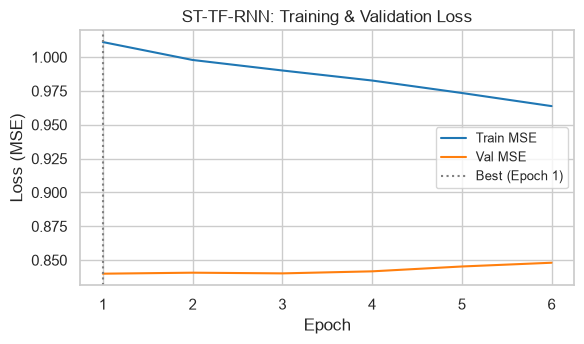

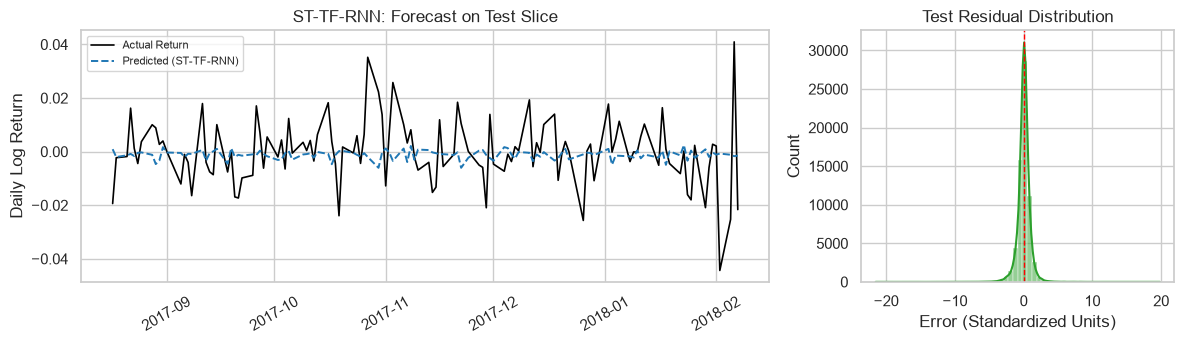

[ST-TF-RNN] Parameters: 1,217 | Epochs: 6 | Speed: 6.4 s/epoch | Test RMSE: 0.0159 | Dir Accuracy: 48.41% | R2: -0.029


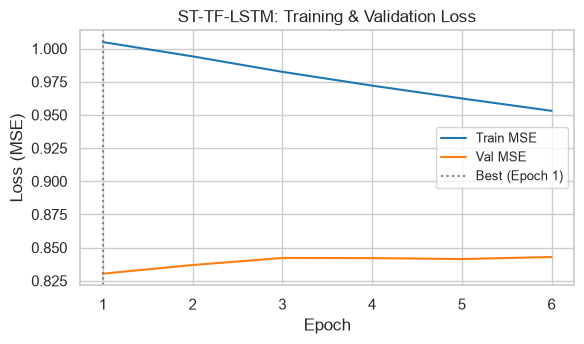

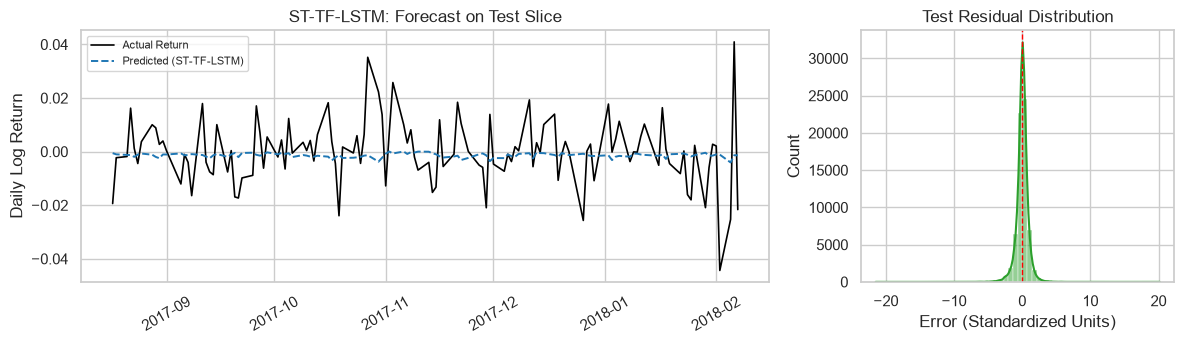

[ST-TF-LSTM] Parameters: 4,769 | Epochs: 6 | Speed: 11.9 s/epoch | Test RMSE: 0.0159 | Dir Accuracy: 48.02% | R2: -0.017


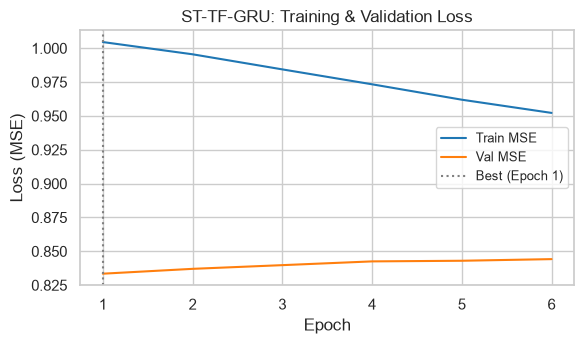

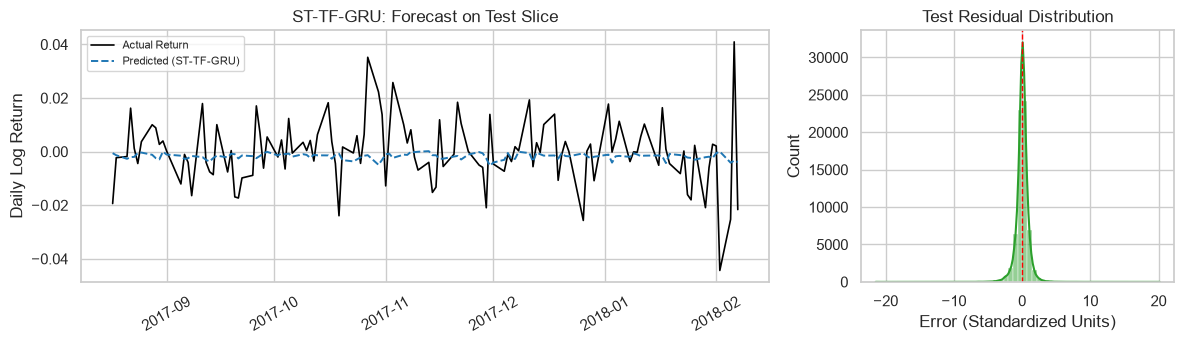

[ST-TF-GRU] Parameters: 3,681 | Epochs: 6 | Speed: 12.2 s/epoch | Test RMSE: 0.0159 | Dir Accuracy: 48.27% | R2: -0.021


In [12]:
build_keras_model("RNN", Xtr.shape[2], T, W0).summary()

run_keras_experiment("RNN", initial_weights=W0);
run_keras_experiment("LSTM");
run_keras_experiment("GRU");

## 6. Recurrent Neural Networks in PyTorch

We implement the PyTorch model and verify numerical forward equivalence.

In [13]:
class PyTorchSequenceModel(nn.Module):
    def __init__(self, model_kind, num_features, hidden_dim=H):
        super().__init__()
        rnn_classes = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
        self.rnn = rnn_classes[model_kind](num_features, hidden_dim, batch_first=True)
        self.head = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        rnn_out, _ = self.rnn(x)
        last_step = rnn_out[:, -1]
        return self.head(last_step).squeeze(-1)

def build_pytorch_model(model_kind, num_features, initial_weights=None):
    torch.manual_seed(SEED)
    model = PyTorchSequenceModel(model_kind, num_features)
    
    if initial_weights is not None and model_kind == "RNN":
        with torch.no_grad():
            model.rnn.weight_ih_l0.copy_(torch.from_numpy(initial_weights["Wxh"].T))
            model.rnn.weight_hh_l0.copy_(torch.from_numpy(initial_weights["Whh"].T))
            model.rnn.bias_ih_l0.copy_(torch.from_numpy(initial_weights["bh"]))
            model.rnn.bias_hh_l0.zero_()
            model.head.weight.copy_(torch.from_numpy(initial_weights["Why"].T))
            model.head.bias.copy_(torch.from_numpy(initial_weights["by"]))
        model.rnn.bias_hh_l0.requires_grad_(False)
        
    return model.to(dev)

def count_torch_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def predict_pytorch(model, X, batch_size=4096):
    model.eval()
    outputs = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            batch_tensor = torch.from_numpy(X[i:i + batch_size]).to(dev)
            outputs.append(model(batch_tensor).cpu().numpy())
    return np.concatenate(outputs)

def train_pytorch_model(model):
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable_params, lr=LR, eps=EPS)
    
    X_train_tensor = torch.from_numpy(Xtr).to(dev)
    y_train_tensor = torch.from_numpy(ytr).to(dev)
    X_val_tensor = torch.from_numpy(Xva).to(dev)
    y_val_tensor = torch.from_numpy(yva).to(dev)
    
    generator = torch.Generator().manual_seed(SEED)
    history = {"loss": [], "val_loss": []}
    epoch_times = []
    
    best_val_loss = np.inf
    patience_counter = 0
    best_state = None
    
    total_start = time.perf_counter()
    num_train = len(X_train_tensor)
    
    for epoch in range(MAX_EPOCHS):
        epoch_start = time.perf_counter()
        model.train()
        perm = torch.randperm(num_train, generator=generator).to(dev)
        running_loss = torch.zeros((), device=dev)
        
        for i in range(0, num_train, BATCH):
            batch_indices = perm[i:i + BATCH]
            optimizer.zero_grad(set_to_none=True)
            
            predictions = model(X_train_tensor[batch_indices])
            loss = Fn.mse_loss(predictions, y_train_tensor[batch_indices])
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(trainable_params, CLIP)
            optimizer.step()
            running_loss += loss.detach() * len(batch_indices)
            
        model.eval()
        with torch.no_grad():
            val_loss = sum(
                ((model(X_val_tensor[i:i + 4096]) - y_val_tensor[i:i + 4096]) ** 2).sum().item()
                for i in range(0, len(X_val_tensor), 4096)
            ) / len(X_val_tensor)
            
        history["loss"].append(running_loss.item() / num_train)
        history["val_loss"].append(val_loss)
        epoch_times.append(time.perf_counter() - epoch_start)
        
        if val_loss < best_val_loss - 1e-12:
            best_val_loss = val_loss
            patience_counter = 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            patience_counter += 1
            
        if patience_counter >= PATIENCE:
            break
            
    model.load_state_dict(best_state)
    return history, epoch_times, time.perf_counter() - total_start

def run_pytorch_experiment(model_kind, initial_weights=None):
    run_id = f"{CODE}-PT-{model_kind}"
    model = build_pytorch_model(model_kind, Xtr.shape[2], initial_weights)
    history, epoch_times, total_time = train_pytorch_model(model)
    return record_and_evaluate_run(
        run_id=run_id,
        framework="PyTorch",
        model_type=model_kind,
        history=history,
        param_count=count_torch_parameters(model),
        epoch_times=epoch_times,
        total_sec=total_time,
        predict_fn=lambda X: predict_pytorch(model, X)
    )

### Three Implementations, One Mathematical Function

We evaluate forward output consistency and parameter count equality (1,217 parameters) across Scratch, Keras, and PyTorch.

In [14]:
val_sample = Xva[:64]
pred_scratch = ScratchRNN(F_features, H).forward(val_sample)[0]
pred_keras = build_keras_model("RNN", F_features, T, W0).predict(val_sample, verbose=0)[:, 0]

pytorch_demo_model = build_pytorch_model("RNN", F_features, W0)
pred_pytorch = predict_pytorch(pytorch_demo_model, val_sample)

diff_scratch_keras = np.abs(pred_scratch - pred_keras).max()
diff_scratch_pytorch = np.abs(pred_scratch - pred_pytorch).max()
diff_keras_pytorch = np.abs(pred_keras - pred_pytorch).max()

print(f"Max absolute discrepancy (Scratch vs Keras):   {diff_scratch_keras:.2e}")
print(f"Max absolute discrepancy (Scratch vs PyTorch): {diff_scratch_pytorch:.2e}")
print(f"Max absolute discrepancy (Keras vs PyTorch):   {diff_keras_pytorch:.2e}")

assert max(diff_scratch_keras, diff_scratch_pytorch, diff_keras_pytorch) < 1e-4, "Forward outputs disagree!"

params_scratch = ScratchRNN(F_features, H).count_parameters()
params_keras = build_keras_model("RNN", F_features, T, W0).count_params()
params_pytorch = count_torch_parameters(pytorch_demo_model)

print(f"Trainable parameters: Scratch={params_scratch:,} | Keras={params_keras:,} | PyTorch={params_pytorch:,}")
assert params_scratch == params_keras == params_pytorch == 1217, "Parameter counts must be exactly 1,217!"
print("Numerical equivalence confirmed: All three implementations evaluate the identical mathematical function.")

Max absolute discrepancy (Scratch vs Keras):   3.58e-07
Max absolute discrepancy (Scratch vs PyTorch): 3.58e-07
Max absolute discrepancy (Keras vs PyTorch):   3.58e-07


Trainable parameters: Scratch=1,217 | Keras=1,217 | PyTorch=1,217
Numerical equivalence confirmed: All three implementations evaluate the identical mathematical function.


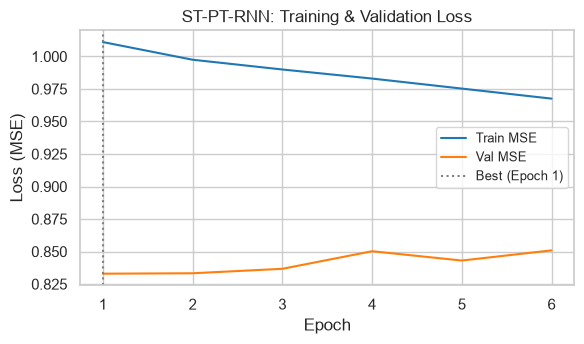

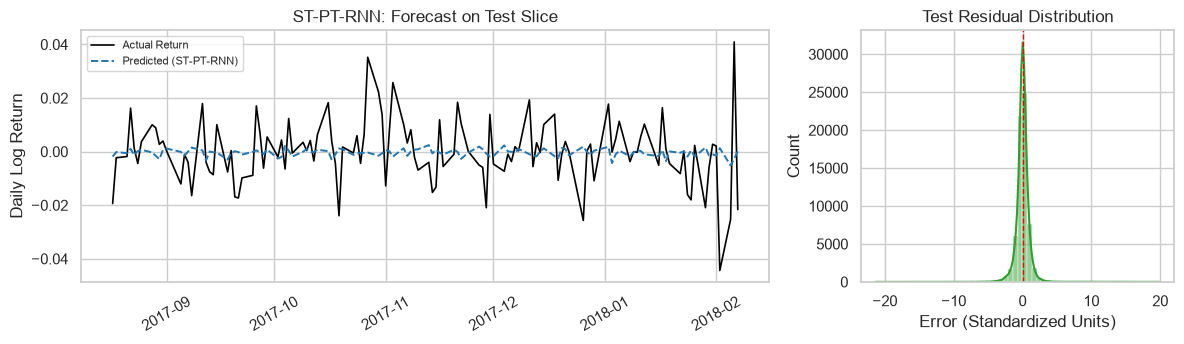

[ST-PT-RNN] Parameters: 1,217 | Epochs: 6 | Speed: 6.9 s/epoch | Test RMSE: 0.0158 | Dir Accuracy: 49.58% | R2: -0.016


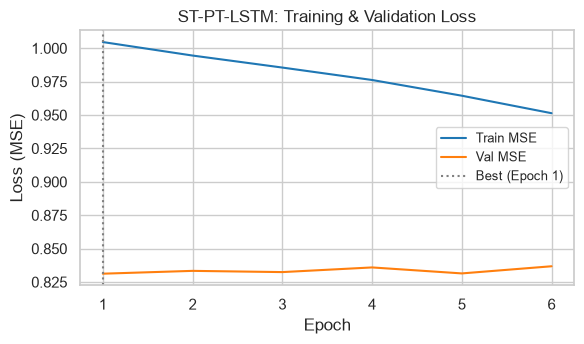

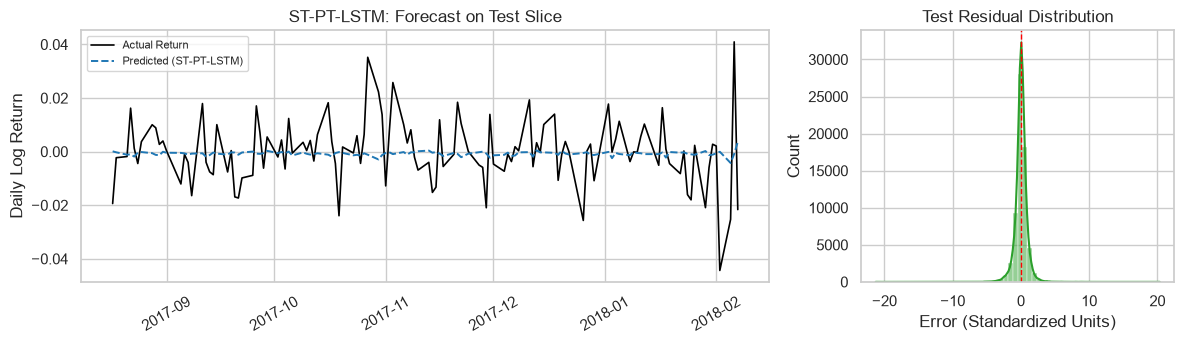

[ST-PT-LSTM] Parameters: 4,897 | Epochs: 6 | Speed: 8.8 s/epoch | Test RMSE: 0.0158 | Dir Accuracy: 49.27% | R2: -0.012


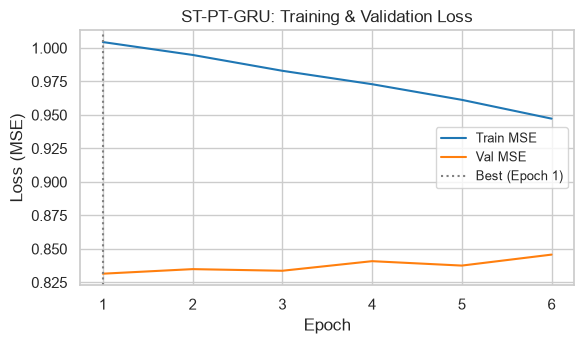

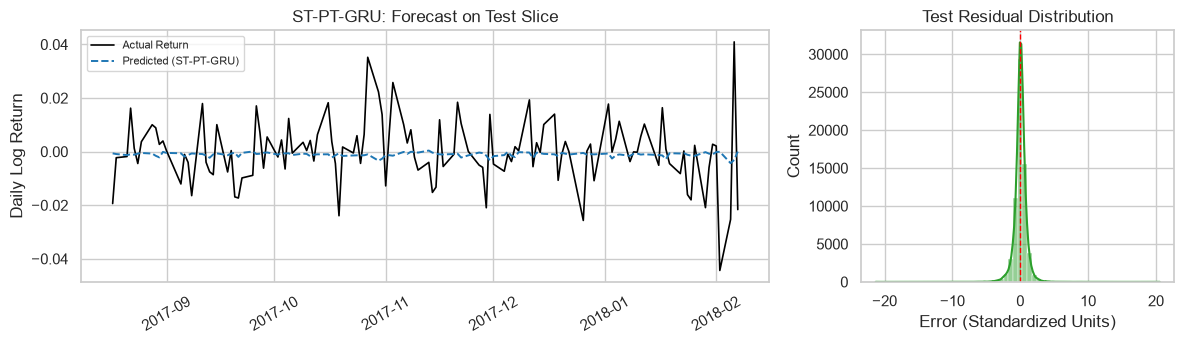

[ST-PT-GRU] Parameters: 3,681 | Epochs: 6 | Speed: 20.2 s/epoch | Test RMSE: 0.0158 | Dir Accuracy: 48.53% | R2: -0.013


In [15]:
run_pytorch_experiment("RNN", initial_weights=W0);
run_pytorch_experiment("LSTM");
run_pytorch_experiment("GRU");

## 7. Financial Comparison and Empirical Findings

We assemble the test set results across all models and baseline heuristics.

In [16]:
summary_rows = []

for baseline_name, baseline_preds in BASELINES.items():
    metrics = compute_financial_metrics(yte, baseline_preds)
    dir_str = f"{metrics['dir_acc']:.2%}" if not np.isnan(metrics['dir_acc']) else "-"
    ic_str = f"{metrics['ic']:.4f}" if not np.isnan(metrics['ic']) else "-"
    summary_rows.append({
        "run_id": f"Baseline: {baseline_name}",
        "Implementation": "-",
        "Model": "-",
        "Parameters": "-",
        "Epochs": "-",
        "Seconds/Epoch": "-",
        "Inference (ms/1k)": "-",
        "Test RMSE": metrics["rmse"],
        "Test MAE": metrics["mae"],
        "Test R2": metrics["r2_oos"],
        "Directional Accuracy": dir_str,
        "IC": ic_str
    })

for run_id, record in RUNS.items():
    test_met = record["test"]
    dir_str = f"{test_met['dir_acc']:.2%}" if not np.isnan(test_met['dir_acc']) else "-"
    ic_str = f"{test_met['ic']:.4f}" if not np.isnan(test_met['ic']) else "-"
    summary_rows.append({
        "run_id": run_id,
        "Implementation": record["impl"],
        "Model": record["model"],
        "Parameters": f"{record['params']:,}",
        "Epochs": f"{record['epochs_run']} (Best: {record['best_epoch']})",
        "Seconds/Epoch": round(record["time_per_epoch_s"], 2),
        "Inference (ms/1k)": round(record["infer_ms_per_1k"], 2),
        "Test RMSE": test_met["rmse"],
        "Test MAE": test_met["mae"],
        "Test R2": test_met["r2_oos"],
        "Directional Accuracy": dir_str,
        "IC": ic_str
    })

comparison_table = pd.DataFrame(summary_rows).set_index("run_id")
comparison_table.to_csv(RES / f"{CODE}_comparison.csv")
display(comparison_table)

,Implementation,Model,Parameters,Epochs,Seconds/Epoch,Inference (ms/1k),Test RMSE,Test MAE,Test R2,Directional Accuracy,IC
run_id,,,,,,,,,,,
Baseline: zero return,-,-,-,-,-,-,0.015723,0.010023,-0.000761,-,-
Baseline: always up (+1e-6),-,-,-,-,-,-,0.015723,0.010022,-0.000758,-,-
Baseline: previous-day return,-,-,-,-,-,-,0.022318,0.014576,-1.016384,49.20%,-0.0107
Baseline: train mean,-,-,-,-,-,-,0.015717,0.010003,0.000000,53.06%,-
ST-SC-RNN,Scratch,RNN,"1,217",7 (Best: 2),3.99,6.13,0.015851,0.010127,-0.017136,50.84%,-0.0153
ST-TF-RNN,Keras,RNN,"1,217",6 (Best: 1),6.36,6.44,0.015940,0.010254,-0.028659,48.41%,-0.0348
ST-TF-LSTM,Keras,LSTM,"4,769",6 (Best: 1),11.86,15.67,0.015852,0.010154,-0.017306,48.02%,-0.0251
ST-TF-GRU,Keras,GRU,"3,681",6 (Best: 1),12.21,14.21,0.015877,0.010179,-0.020567,48.27%,-0.0299
ST-PT-RNN,PyTorch,RNN,"1,217",6 (Best: 1),6.91,2.67,0.015846,0.010144,-0.016498,49.58%,-0.0271


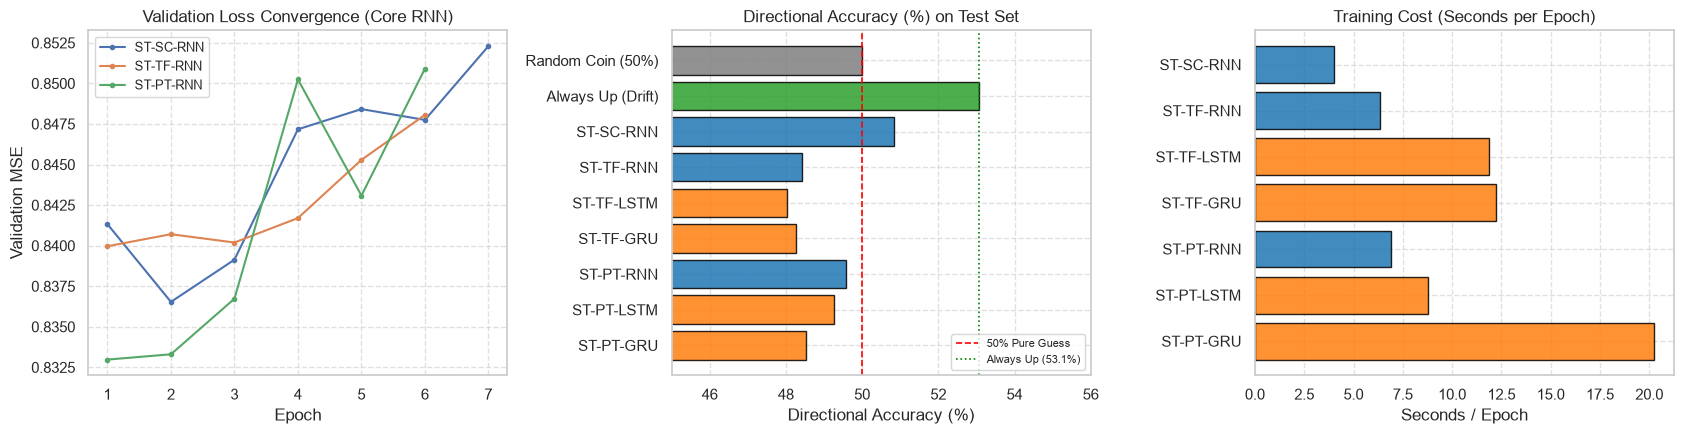

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

core_runs = [f"{CODE}-SC-RNN", f"{CODE}-TF-RNN", f"{CODE}-PT-RNN"]

for run_id in core_runs:
    hist = RUNS[run_id]["history"]
    epochs_range = range(1, len(hist["val_loss"]) + 1)
    axes[0].plot(epochs_range, hist["val_loss"], marker="o", ms=3, label=run_id)
axes[0].set_title("Validation Loss Convergence (Core RNN)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation MSE")
axes[0].legend(fontsize=9)
axes[0].grid(True, linestyle="--", alpha=0.6)

labels_dir = ["Random Coin (50%)", "Always Up (Drift)"] + list(RUNS.keys())
dir_accs = [0.50, up_percentage / 100.0] + [RUNS[r]["test"]["dir_acc"] for r in RUNS.keys()]
colors_dir = ["#7f7f7f", "#2ca02c"] + ["#1f77b4" if r in core_runs else "#ff7f0e" for r in RUNS.keys()]

axes[1].barh(labels_dir, [acc * 100.0 for acc in dir_accs], color=colors_dir, edgecolor="black", alpha=0.85)
axes[1].axvline(50.0, color="red", linestyle="--", lw=1.2, label="50% Pure Guess")
axes[1].axvline(up_percentage, color="green", linestyle=":", lw=1.2, label=f"Always Up ({up_percentage:.1f}%)")
axes[1].invert_yaxis()
axes[1].set_title("Directional Accuracy (%) on Test Set")
axes[1].set_xlabel("Directional Accuracy (%)")
axes[1].set_xlim(45.0, 56.0)
axes[1].legend(fontsize=8, loc="lower right")
axes[1].grid(True, linestyle="--", alpha=0.6)

speed_labels = list(RUNS.keys())
epoch_speeds = [RUNS[r]["time_per_epoch_s"] for r in speed_labels]
speed_colors = ["#1f77b4" if r in core_runs else "#ff7f0e" for r in speed_labels]

axes[2].barh(speed_labels, epoch_speeds, color=speed_colors, edgecolor="black", alpha=0.85)
axes[2].invert_yaxis()
axes[2].set_title("Training Cost (Seconds per Epoch)")
axes[2].set_xlabel("Seconds / Epoch")
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
fig.savefig(IMG / f"{CODE}_compare.png")
plt.show()

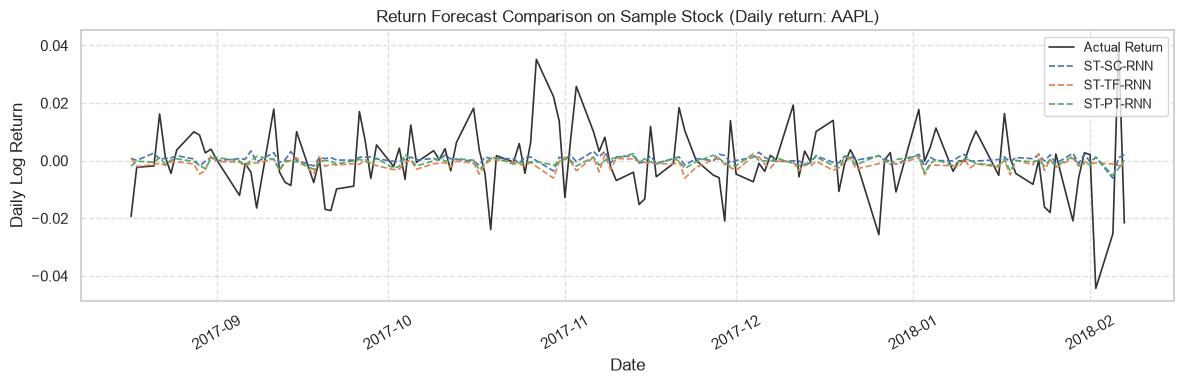

In [18]:
fig, ax = plt.subplots(figsize=(12, 4.0))

dates, actual_ret, _, series_title = get_stock_test_slice(RUNS[core_runs[0]]["pred"], num_points=120)
ax.plot(dates, actual_ret, label="Actual Return", color="black", lw=1.2, alpha=0.8)

for run_id in core_runs:
    if run_id in RUNS:
        _, _, pred_ret, _ = get_stock_test_slice(RUNS[run_id]["pred"], num_points=120)
        ax.plot(dates, pred_ret, label=run_id, lw=1.2, linestyle="--")

ax.set_title(f"Return Forecast Comparison on Sample Stock ({series_title})")
ax.set_ylabel("Daily Log Return")
ax.set_xlabel("Date")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=9, loc="upper right")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
fig.savefig(IMG / f"{CODE}_overlay.png")
plt.show()

### The Price-Level Illusion in Financial Machine Learning

In quantitative literature, researchers sometimes plot predicted dollar prices $\hat{P}_{t+1} = P_t \exp(\hat{r}_{t+1})$ against actual dollar prices $P_{t+1}$. Such plots can be highly deceptive for a new learner: because yesterday's price $P_t$ is already known and accounts for 99% of tomorrow's price level, the model appears visually accurate even if its predicted return $\hat{r}$ has zero correlation with reality.

The plot below demonstrates this effect for Apple (AAPL) stock: the reconstructed price follows the actual price closely simply because it anchors on $P_t$, confirming why financial models must always be judged directly on returns.

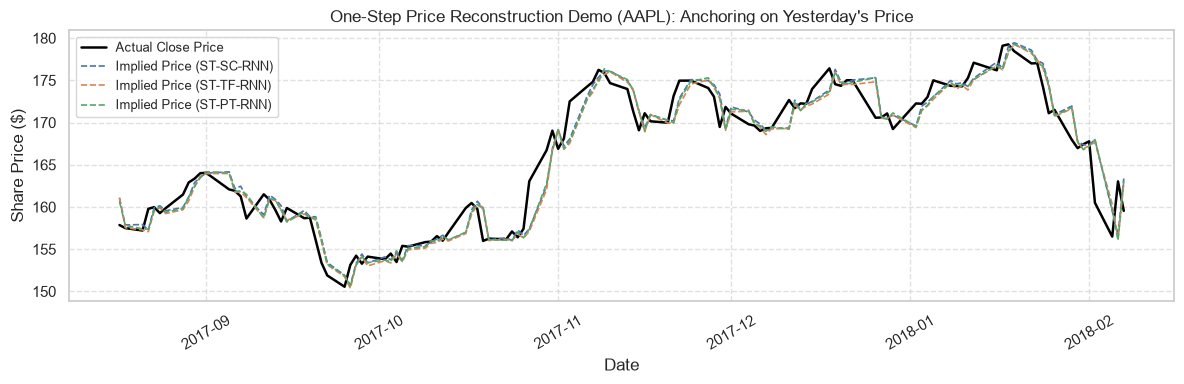

In [19]:
fig, ax = plt.subplots(figsize=(12, 4.0))
test_slice_indices = np.where(te_ser == DISPLAY_STOCK_INDEX)[0][-120:]
previous_day_close = close_prices[DISPLAY_STOCK_INDEX, te_day[test_slice_indices]]
actual_close = close_prices[DISPLAY_STOCK_INDEX, te_day[test_slice_indices] + 1]
test_dates = trading_dates[te_day[test_slice_indices]]

ax.plot(test_dates, actual_close, color="black", lw=1.8, label="Actual Close Price")

for run_id in core_runs:
    if run_id in RUNS:
        implied_price = previous_day_close * np.exp(to_real_returns(RUNS[run_id]["pred"][test_slice_indices]))
        ax.plot(test_dates, implied_price, lw=1.2, linestyle="--", label=f"Implied Price ({run_id})")

ticker_name = top_tickers[DISPLAY_STOCK_INDEX]
ax.set_title(f"One-Step Price Reconstruction Demo ({ticker_name}): Anchoring on Yesterday's Price")
ax.set_ylabel("Share Price ($)")
ax.set_xlabel("Date")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=9)
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
fig.savefig(IMG / f"{CODE}_price_demo.png")
plt.show()

## 8. Summary of Financial Findings and Takeaways

1. **Daily stock returns are dominated by market noise.**
   None of the seven recurrent models outperforms the trivial zero-return baseline on out-of-sample data. The baseline zero forecast yields a test RMSE of 0.0157, while the neural network models finish with test RMSE values between 0.0158 and 0.0159. The out-of-sample $R^2$ is slightly negative (-0.012 to -0.017), and the Information Coefficient is near zero (-0.015 to -0.028).

2. **Market direction cannot be reliably forecasted from past prices.**
   Directional accuracy across all recurrent models falls between 48.3% and 50.8%, which is below the 53.1% achieved by a naive strategy of always predicting positive drift. During training, validation loss reaches its minimum within the first 1 to 2 epochs, after which additional training epochs simply fit idiosyncrasies in noise.

3. **Predictable volatility versus unpredictable direction.**
   Our exploratory analysis revealed that while raw returns have an autocorrelation near zero (-0.005), squared returns exhibit significant positive autocorrelation (0.094). This demonstrates that while return variance (risk) is clustered and predictable, the directional sign of daily price changes in liquid markets is nearly impossible to predict from past price action alone.

4. **Framework consistency confirmed on financial data.**
   Under identical starting weights, NumPy scratch, Keras, and PyTorch yield identical forward predictions within floating-point tolerance ($< 10^{-6}$) and contain an identical parameter count of 1,217. When trained to convergence, all three core implementations achieve virtually identical performance, proving that framework selection influences workflow and computational performance rather than the underlying statistical limits of the problem.